In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder
import re

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import Ridge, Lasso, LinearRegression
import xgboost as xgb
import lightgbm as lgb
!pip install catboost
from catboost import CatBoostRegressor
import random
from sklearn.neighbors import KNeighborsRegressor
import matplotlib.pyplot as plt


/usr/local/lib/python3.10/dist-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 MB 7.6 MB/s eta 0:00:00


In [2]:
train = pd.read_csv("./train_feature_v3.csv",index_col=0)
test = pd.read_csv("./test_feature_v3.csv",index_col=0)

### Apply PCA (optional)

In [ ]:
def load_and_clean_csv(file_path):
    df = pd.read_csv(file_path)
    df = df.rename(columns=lambda x: re.sub('[^A-Za-z0-9_]+', '', x))
    return df


def apply_pca(df, columns_range, n_components, suffix=""):
    le = LabelEncoder()
    selected_cols = df.iloc[:, columns_range]
    encoded_cols = selected_cols.apply(le.fit_transform)

    pca = PCA(n_components=n_components)
    pca_result = pca.fit_transform(encoded_cols)
    pca_result_df = pd.DataFrame(pca_result, columns=[f'pca_{i}{suffix}' for i in range(n_components)])

    # Reset index of pca_result_df to align with df
    pca_result_df.reset_index(drop=True, inplace=True)
    df = df.drop(columns=selected_cols.columns, errors='ignore')
    df = pd.concat([df, pca_result_df], axis=1)
    return df

# Load and clean data
train2 = load_and_clean_csv('./train_feature_v3.csv')
test2 = load_and_clean_csv('./test_feature_v3.csv')

# Apply first PCA transformation (columns 5 to 27, 5 components)
train2 = apply_pca(train2, slice(5, 27), 5)
test2 = apply_pca(test2, slice(5, 27), 5)

# Apply second PCA transformation (columns 7 to 13, 3 components, with '_double' suffix)
train2 = apply_pca(train2, slice(7, 13), 3, suffix="_double")
test2 = apply_pca(test2, slice(7, 13), 3, suffix="_double")


train = train2
test = test2


### Splitting and Scaling

In [3]:
X = train.drop(columns=['price'])
y = train['price']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, random_state=42)

In [ ]:
scaler = StandardScaler()

# Fit on training data and transform both training and validation sets
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
test_scaled = scaler.fit_transform(test)

# 1 Individual Regressors

## 1.1 Random Forest Regressor

#### Model and fit methods for the random forest

In [ ]:
# Initialize the RandomForestRegressor with some standard parameters
model = RandomForestRegressor(
    n_estimators=200,         # Number of trees in the forest
    max_depth=100,             # Maximum depth of each tree
    random_state=42,          # Ensures reproducibility
    n_jobs=-1,                 # Use all processors for parallel training
    max_features=50
)

# Train the model
model.fit(X_train, y_train)


RandomForestRegressor(max_depth=100, max_features=50, n_estimators=200,
                      n_jobs=-1, random_state=42)

#### Make Validation prediction with error

In [ ]:
test_on_submission = False

if test_on_submission:
    #Write the prediction on the test set into a csv file for submission
    test_predictions = model.predict(test)

    predictions_df = pd.DataFrame(test_predictions, columns=['Predicted'])
    predictions_df.to_csv("test_prediction_random_forest.csv", index=True, index_label="Id")
else:
    #Make a prediction on the validation set and output the RMSE
    y_val_pred = model.predict(X_val)

    mse = mean_squared_error(y_val, y_val_pred)
    rmse = np.sqrt(mse)
    print("Random Forest RMSE:", rmse)


Random Forest RMSE: 26501.607161300093


#### Perform Grid search

In [ ]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 30, 50],
    'max_features': [30, 35, 40],
    'min_samples_split': [2],
    'min_samples_leaf': [1]
}
base_model = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',  # Use negative MSE for regression
    cv=5,                              # 5-fold cross-validation
    n_jobs=-1,                         # Use all available cores
    verbose=0                          # Controls the verbosity: the higher, the more messages
)
grid_search.fit(X_train, y_train)

print("Best Hyperparameters:", grid_search.best_params_)

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_val)

# Calculate RMSE
mse = mean_squared_error(y_val, y_pred)
rmse = np.sqrt(mse)
print("Random Forest RMSE:", rmse)


Best Hyperparameters: {'max_depth': 30, 'max_features': 40, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Random Forest RMSE: 25822.347454391856


## 1.2 Linear Regressor

#### Model fitting

In [ ]:
use_ridge = True


# Extract best model from Ridge or Lasso based on the better MSE score
if use_ridge:
    model_linreg = Ridge(alpha = 100)
else:
    model_linreg = Lasso(alpha = 100)

# Fit the final model on the full training data
model_linreg.fit(X_train_scaled, y_train)

LinearRegression()

In [ ]:
test_on_submission = False

if test_on_submission:
    #Write the prediction on the test set into a csv file for submission
    test_predictions = model_linreg.predict(test_scaled)

    predictions_df = pd.DataFrame(test_predictions, columns=['Predicted'])
    predictions_df.to_csv("test_prediction_linear_regressor.csv", index=True, index_label="Id")
else:
    #Make a prediction on the validation set and output the RMSE
    y_val_pred = model_linreg.predict(X_val_scaled)

    mse = mean_squared_error(y_val, y_val_pred)
    rmse = np.sqrt(mse)
    print("Linear Regressor RMSE:", rmse)


#### Grid search for Lasso and Ridge

In [ ]:
ridge_params = {'alpha': [100, 200 ,300, 400 ,500]}
lasso_params = {'alpha': [100, 200 ,300, 400 ,500]}
ridge = Ridge()
lasso = Lasso()

ridge_grid_search = GridSearchCV(ridge, ridge_params, scoring='neg_mean_squared_error', cv=5)
lasso_grid_search = GridSearchCV(lasso, lasso_params, scoring='neg_mean_squared_error', cv=5)

#Ridge model fitting
ridge_grid_search.fit(X_train_scaled, y_train)
ridge_best_model = ridge_grid_search.best_estimator_
ridge_best_score = -ridge_grid_search.best_score_  # Convert negative MSE to positive for interpretability

#Lasso model fitting
lasso_grid_search.fit(X_train_scaled, y_train)
lasso_best_model = lasso_grid_search.best_estimator_
lasso_best_score = -lasso_grid_search.best_score_

print("Best Ridge model:", ridge_best_model)
ridge_best_score = np.sqrt(ridge_best_score)
print("Best Ridge RMSE:", ridge_best_score)

print("Best Lasso model:", lasso_best_model)
lasso_best_score = np.sqrt(lasso_best_score)
print("Best Lasso RMSE:", lasso_best_score)


Best Ridge model: Ridge(alpha=100)
Best Ridge RMSE: 43228.383158409044
Best Lasso model: Lasso(alpha=100)
Best Lasso RMSE: 43313.98942347318


## 1.3 K Neighbour Regression


In [ ]:
knn_model = KNeighborsRegressor(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)


KNeighborsRegressor()

In [ ]:
test_on_submission = False

if test_on_submission:
    #Write the prediction on the test set into a csv file for submission
    test_predictions = knn_model.predict(test_scaled)

    predictions_df = pd.DataFrame(test_predictions, columns=['Predicted'])
    predictions_df.to_csv("test_prediction_KNN.csv", index=True, index_label="Id")
else:
    #Make a prediction on the validation set and output the RMSE
    y_val_pred = knn_model.predict(X_val_scaled)

    mse = mean_squared_error(y_val, y_val_pred)
    rmse = np.sqrt(mse)
    print("KNN RMSE:", rmse)


KNN RMSE: 38631.32755414134


#### Search for best neighbour amount

In [ ]:
errors = []
neighbors = range(1, 20)  # Test from 1 to 20 neighbors

for k in neighbors:
    knn_model = KNeighborsRegressor(n_neighbors=k)
    knn_model.fit(X_train_scaled, y_train)
    y_val_pred = knn_model.predict(X_val_scaled)
    mse = mean_squared_error(y_val, y_val_pred)
    errors.append(mse)

# Find the k with the lowest MSE
optimal_k = neighbors[errors.index(min(errors))]
mse = min(errors)
rmse = np.sqrt(mse)
print("Optimal number of neighbors: ", optimal_k)
print("Resulting RMSE: ", rmse)


Optimal number of neighbors:  5
Resulting RMSE:  38631.32755414134


## 1.4 Gradient Boosting Trees

### XGB Regressor

#### Model creation and fitting

In [4]:
mod_xgb = xgb.XGBRegressor(
      colsample_bytree= 1.0,
      gamma= 1,
      learning_rate= 0.1,
      max_depth= 5,
      n_estimators= 1000,
      subsample= 0.9,
      random_state=42)



mod_xgb.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose = False
    )


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=1.0, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=1, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.1, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=5, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1000, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

#### Model evaluation

In [5]:
test_on_submission = False

if test_on_submission:
    #Write the prediction on the test set into a csv file for submission
    test_predictions = mod_xgb.predict(test)

    predictions_df = pd.DataFrame(test_predictions, columns=['Predicted'])
    predictions_df.to_csv("test_prediction_xgb_indiv.csv", index=True, index_label="Id")
else:
    #Make a prediction on the validation set and output the RMSE
    y_val_pred = mod_xgb.predict(X_val)

    mse = mean_squared_error(y_val, y_val_pred)
    rmse = np.sqrt(mse)
    print("XGB Regressor RMSE:", rmse)



XGB Regressor RMSE: 26652.535593999426


### LightGBM Regressor

In [6]:
gbm = lgb.LGBMRegressor(
    objective = 'regression',
    metric = 'rmse',            # Metric for regression
    boosting_type = 'gbdt',      # Gradient Boosting Decision Tree
    learning_rate = 0.1,
    verbose = -1,
    max_depth = 5,
    num_leaves = 31,
    subsample = 0.8,
    n_estimators = 1000,
    colsample_bytree = 0.8,
    reg_lambda = 0.2,
    early_stopping_rounds = 50)

gbm.fit(X_train, y_train,
        eval_set=(X_val, y_val))

LGBMRegressor(colsample_bytree=0.8, early_stopping_rounds=50, max_depth=5,
              metric='rmse', n_estimators=1000, objective='regression',
              reg_lambda=0.2, subsample=0.8, verbose=-1)

In [7]:
test_on_submission = False

if test_on_submission:
    #Write the prediction on the test set into a csv file for submission
    test_predictions = gbm.predict(test)

    predictions_df = pd.DataFrame(test_predictions, columns=['Predicted'])
    predictions_df.to_csv("test_prediction_LGB_indiv.csv", index=True, index_label="Id")
else:
    #Make a prediction on the validation set and output the RMSE
    y_val_pred = gbm.predict(X_val)

    mse = mean_squared_error(y_val, y_val_pred)
    rmse = np.sqrt(mse)
    print("LightGBM Regressor RMSE:", rmse)

LightGBM Regressor RMSE: 26588.693239536802


### Catboost Regressor

In [8]:
cat_model = CatBoostRegressor(iterations=1000, learning_rate=0.1, depth=5, random_seed=42, verbose= 0)

cat_model.fit(X_train, y_train, eval_set=(X_val, y_val))

In [9]:
test_on_submission = False

if test_on_submission:
    #Write the prediction on the test set into a csv file for submission
    test_predictions = cat_model.predict(test)

    predictions_df = pd.DataFrame(test_predictions, columns=['Predicted'])
    predictions_df.to_csv("test_prediction_cb_indiv.csv", index=True, index_label="Id")
else:
    #Make a prediction on the validation set and output the RMSE
    y_val_pred = cat_model.predict(X_val)

    mse = mean_squared_error(y_val, y_val_pred)
    rmse = np.sqrt(mse)
    print("Catboost Regressor RMSE:", rmse)

Catboost Regressor RMSE: 26107.43339261841


# Ensembles

#### Test of 3 Gradient Boosting Regerssors combined

In [12]:
test_on_submission = True

if test_on_submission:
    #Write the prediction on the test set into a csv file for submission
    y_pred_1 = mod_xgb.predict(test)
    y_pred_2 = gbm.predict(test)
    y_pred_3 = cat_model.predict(test)
    y_pred = (y_pred_1) * 0.33 + (y_pred_2) * 0.33 + (y_pred_3) * 0.33

    predictions_df = pd.DataFrame(y_pred, columns=['Predicted'])
    predictions_df.to_csv("test_prediction_combined_v6.csv", index=True, index_label="Id")
else:
    #Make a prediction on the validation set and output the RMSE
    y_pred_1 = mod_xgb.predict(X_val)
    y_pred_2 = gbm.predict(X_val)
    y_pred_3 = cat_model.predict(X_val)
    y_pred = (y_pred_1) * 0.33 + (y_pred_2) * 0.33 + (y_pred_3) * 0.33

    mse = mean_squared_error(y_val, y_pred)
    rmse = np.sqrt(mse)
    print("Combined GB RMSE:", rmse)


Combined GB RMSE: 25636.86223554535


<h2> Plot strip graph for ensemble model

In [13]:
def plot_outl(actual,predicted):
    # Calculate the signed offset (difference) between actual and predicted values

    # Calculate the signed offset (difference) between actual and predicted values
    offsets = predicted - actual

    # Find the minimum and maximum offset
    min_offset = np.floor(np.min(offsets) / 200000) * 200000  # Round down to the nearest 200,000
    max_offset = np.ceil(np.max(offsets) / 200000) * 200000   # Round up to the nearest 200,000

    # Set up tick marks for every 200,000 interval, plus min and max
    ticks = np.arange(min_offset, max_offset + 1, 100000)

    # Set up the plot
    plt.figure(figsize=(14, 2))  # Wide and short figure for a strip plot

    # Plot each offset as a point, with larger markers and outlines
    plt.scatter(offsets, np.zeros_like(offsets), facecolors='skyblue', edgecolors='black', s=10, alpha=0.5)

    # Customize plot
    plt.xlabel('Prediction Offset in Millions')
    plt.title('Horizontal Strip Plot of Prediction Offsets')
    plt.yticks([])  # Remove y-axis ticks for a cleaner look
    plt.axvline(0, color='red', linestyle='dashed', linewidth=1)  # Reference line at zero

    # Set x-axis limits and add custom ticks
    plt.xlim(min_offset, max_offset)
    plt.xticks(ticks)

    # Show plot
    plt.show()

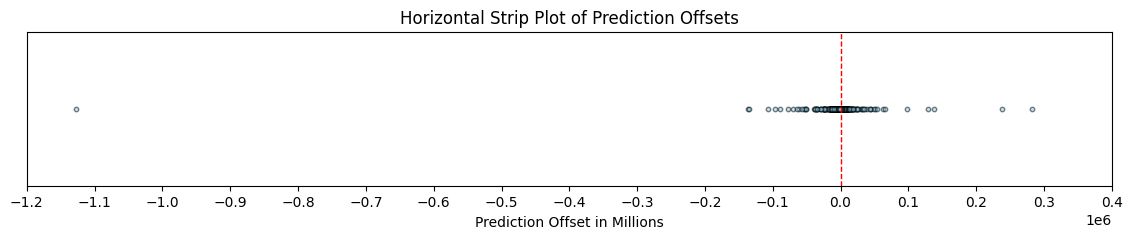

In [14]:
plot_outl(y_val,y_pred)

<h2> Plot distribution graph for ensemble model

In [15]:
def plot_dist(actual,predicted, cut_at = 100000):
    # Calculate offset (error) between actual and predicted values
    # actual = np.random.normal(loc=0, scale=1000, size=int(300000 * 0.2))  # Replace with your actual data array
    # predicted = actual + np.random.normal(loc=0, scale=500, size=int(300000 * 0.2))  # Replace with your prediction data array

    # Calculate the signed offset (difference) between actual and predicted values
    offsets = predicted - actual

    # Determine maximum absolute offset to set range for the x-axis
    max_offset = np.ceil(np.max(np.abs(offsets)) / 100) * 100  # Round up to nearest 100

    # Define bucket ranges for the offsets with a width of 100
    bin_width = 100
    bins = np.arange(-max_offset, max_offset + bin_width, bin_width)  # Symmetrical around zero
    hist, bin_edges = np.histogram(offsets, bins=bins)  # Count occurrences in each bin

    # Midpoints of each bin for x-axis labels
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Plot column graph
    plt.figure(figsize=(14, 6))
    plt.bar(bin_centers, hist, width=bin_width, edgecolor='black', color='skyblue')
    plt.xlabel('Prediction Offset (Predicted - Actual)')
    plt.ylabel('Number of Data Points')
    plt.title('Distribution of Prediction Offsets')

    # Set x-axis limits and labels every 1000 steps
    plt.xlim(-cut_at, cut_at)
    plt.xticks(np.arange(-cut_at, cut_at + 1, (cut_at*0.1)))  # Set ticks at every 1000 for readability

    # Add a reference line at zero
    plt.axvline(0, color='red', linestyle='dashed', linewidth=1)

    # Display grid only on the y-axis for readability
    plt.grid(axis='y', linestyle='--', alpha=0.6)

    # Show plot
    plt.show()

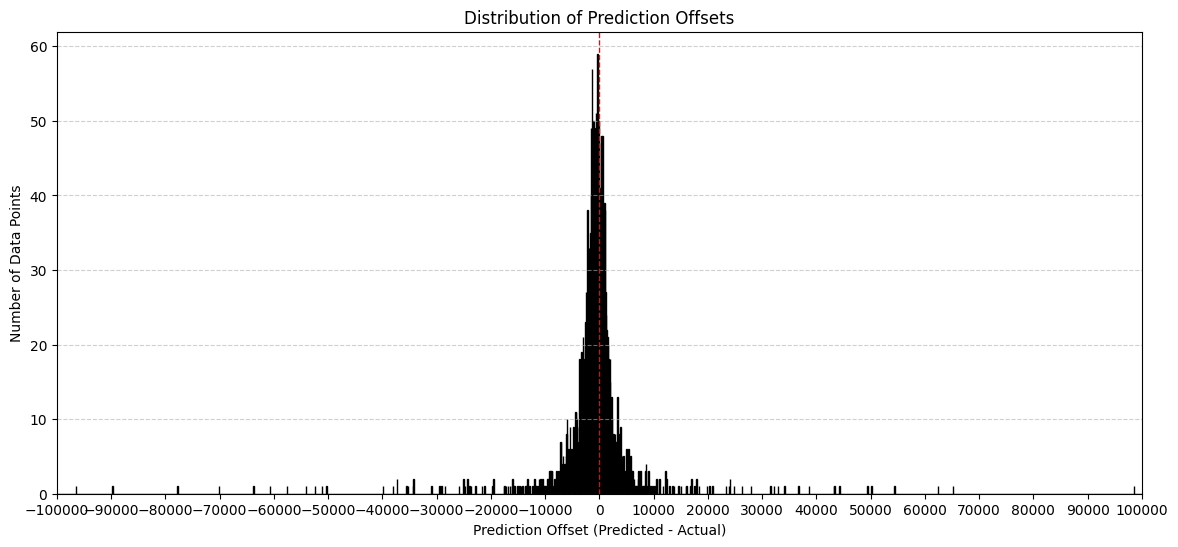

In [16]:
plot_dist(y_val,y_pred)